In [1]:
# Среда разработки anaconda (Python 3.12.7)

# Загрузка необходимых библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, roc_auc_score, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
import xgboost as xgb
import pickle
import warnings
warnings.filterwarnings('ignore')

# Настройка стиля графиков
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

In [2]:
# Загрузим датасет с сформированными на тренировочной выборке (до 01/09/2015) признаками item-ов 

items_data = pd.read_csv("items_data.csv")

items_data.info()
items_data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466868 entries, 0 to 466867
Data columns (total 28 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   itemid                           466868 non-null  int64  
 1   item_popularity_global           466868 non-null  int64  
 2   item_popularity_global_weighted  466868 non-null  int64  
 3   item_conversion_rate             466868 non-null  float64
 4   cart_to_view_ratio               466868 non-null  float64
 5   item_unique_users                466868 non-null  int64  
 6   item_popularity_7d               466868 non-null  int64  
 7   item_popularity_30d              466868 non-null  int64  
 8   item_popularity_trend            466868 non-null  float64
 9   days_since_last_interaction      466868 non-null  int64  
 10  category_ids                     466868 non-null  object 
 11  item_age                         466868 non-null  float64
 12  it

,itemid,item_popularity_global,item_popularity_global_weighted,item_conversion_rate,cart_to_view_ratio,item_unique_users,item_popularity_7d,item_popularity_30d,item_popularity_trend,days_since_last_interaction,...,is_new_item,efficiency_score,property_age,num_categories,categories_volatility,category_ids_list,item_avg_embedding,item_sum_embedding,item_max_embedding,item_weighted_embedding
0,0,0,0,0.0,0.0,0,0,0,0.0,0,...,0,0.0,114,128,"[{227: 1}, {11: 1}, {189: 1}, {202: 1}, {888: ...","[227, 11, 189, 202, 888, 283, 177, 127, 112, 4...",[ 3.56856308e-01 -1.04362308e-01 1.85412049e-...,[ 8.20769509e+00 -2.40033308e+00 4.26447712e+...,[1.38677204 0.67742497 0.95805448 0.56929392 0...,[ 3.15680593e-01 -9.23205018e-02 1.64018348e-...
1,1,0,0,0.0,0.0,0,0,0,0.0,0,...,0,0.0,114,159,"[{280: 1}, {284: 1}, {664: 1}, {227: 1}, {202:...","[280, 284, 664, 227, 202, 888, 283, 112, 768, ...",[ 4.86354482e-01 -1.47178513e-01 1.44639546e-...,[ 1.36179255e+01 -4.12099837e+00 4.04990728e+...,[2.1673646 0.67742497 1.08613145 0.56929392 1...,[ 4.12664413e-01 -1.24878734e-01 1.22724459e-...
2,2,0,0,0.0,0.0,0,0,0,0.0,0,...,0,0.0,114,111,"[{202: 1}, {888: 1}, {283: 1}, {877: 1}, {112:...","[202, 888, 283, 877, 112, 332, 776, 698, 790, ...",[ 0.37457673 -0.12320846 0.16825244 -0.010039...,[ 7.86611123 -2.5873776 3.53330126 -0.21...,[1.38677204 0.52465641 0.95805448 0.56929392 0...,[ 0.3575505 -0.11760808 0.16060461 -0.009582...
3,3,2,2,0.0,0.0,2,1,2,1.0,0,...,0,0.0,114,133,"[{459: 1}, {227: 1}, {250: 1}, {202: 1}, {888:...","[459, 227, 250, 202, 888, 283, 1080, 30, 112, ...",[ 0.37151908 -0.13029113 0.10465119 0.041238...,[ 8.91645795 -3.12698708 2.51162846 0.98...,[1.38677204 0.67742497 0.95805448 0.67742455 0...,[ 0.33023918 -0.11581434 0.09302326 0.036656...
4,4,2,2,0.0,0.0,2,1,1,0.0,0,...,0,0.0,114,106,"[{897: 1}, {227: 1}, {28: 1}, {202: 1}, {888: ...","[897, 227, 28, 202, 888, 283, 112, 689, 981, 8...",[ 0.46195079 -0.08893096 0.14741269 -0.000763...,[ 9.70096656 -1.86755014 3.09566647 -0.016042...,[1.38677204 0.67742497 0.99235409 0.60152012 0...,[ 0.44095304 -0.08488864 0.14071212 -0.000729...


In [3]:
# Загрузим датасет с сформированными на тренировочной выборке (до 01/09/2015) признаками item-user

item_user = pd.read_csv("item_user.csv")

item_user.info()
item_user.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1903950 entries, 0 to 1903949
Data columns (total 25 columns):
 #   Column                                    Dtype  
---  ------                                    -----  
 0   User ID                                   int64  
 1   Item ID                                   int64  
 2   user_item_click_count                     int64  
 3   user_item_cart_count                      int64  
 4   user_item_purchase_count                  int64  
 5   days_since_last_user_item_interaction     int64  
 6   visitorid                                 int64  
 7   itemid                                    int64  
 8   user_item_first_interaction_date          int64  
 9   item_category                             float64
 10  item_in_user_top_categories               int64  
 11  user_cat_affinity_vs_item_cat             float64
 12  user_peak_hour                            int64  
 13  item_peak_hour                            int64  
 14  us

,User ID,Item ID,user_item_click_count,user_item_cart_count,user_item_purchase_count,days_since_last_user_item_interaction,visitorid,itemid,user_item_first_interaction_date,item_category,...,user_activity_trend_7d,item_popularity_trend_7d,user_item_recency,user_item_interaction_score,user_item_interaction_score_normalized,user_item_similarity,user_item_similarity_normalized,similarity_group,user_item_property_similarity,user_item_property_similarity_normalized
0,257597,355908,1,0,0,90,257597,355908,90,227.0,...,0.0,0.986755,0.0,1.167916e-03,0.166243,0.938131,0.969065,Сильно полож,0.996075,0.998038
1,992329,248676,1,0,0,90,992329,248676,90,227.0,...,0.0,0.000000,0.0,1.250310e-03,0.166288,0.042442,0.521221,Слабо отриц,0.966103,0.983051
2,111016,318965,2,0,0,90,111016,318965,92,NaN,...,0.0,0.000000,0.0,2.296975e-11,0.165594,0.978458,0.989229,Сильно полож,0.000000,0.500000
3,483717,253185,2,0,0,90,483717,253185,90,227.0,...,0.0,0.818182,0.0,5.441788e-13,0.165594,0.982715,0.991358,Сильно полож,1.000000,1.000000
4,951259,367447,1,0,0,90,951259,367447,90,227.0,...,0.0,-0.090909,-0.0,1.194268e-02,0.172231,0.950284,0.975142,Сильно полож,1.000000,1.000000


In [4]:
# Загрузим датасет с событиями на тренировочной выборке (до 01/09/2015)

data_events_train = pd.read_csv("data_events_train.csv")

data_events_train.info()
data_events_train.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2450177 entries, 0 to 2450176
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   dt             object 
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 93.5+ MB


,dt,visitorid,event,itemid,transactionid
0,2015-06-02 07:02:12.117,257597,view,355908,NaN
1,2015-06-02 07:50:14.164,992329,view,248676,NaN
2,2015-06-02 07:13:19.827,111016,view,318965,NaN
3,2015-06-02 07:12:35.914,483717,view,253185,NaN
4,2015-06-02 07:02:17.106,951259,view,367447,NaN


In [5]:
# Загрузим датасет с событиями на тестовой выборке (после 01/09/2015)

data_events_test = pd.read_csv("data_events_test.csv")

data_events_test.info()
data_events_test.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 305924 entries, 0 to 305923
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   dt             305924 non-null  object 
 1   visitorid      305924 non-null  int64  
 2   event          305924 non-null  object 
 3   itemid         305924 non-null  int64  
 4   transactionid  2397 non-null    float64
dtypes: float64(1), int64(2), object(2)
memory usage: 11.7+ MB


,dt,visitorid,event,itemid,transactionid
0,2015-09-01 06:57:52.374,138734,view,139298,NaN
1,2015-09-01 06:56:20.262,938236,view,374698,NaN
2,2015-09-01 07:40:29.058,1016904,view,294319,NaN
3,2015-09-01 06:59:31.340,349857,view,277328,NaN
4,2015-09-01 07:24:38.078,843815,view,42267,NaN


**План экспериментов :**
1.	Коллаборативная фильтрация;
2.	Факторизационные машины;
3.	XGBoost для задачи классификации.

In [6]:
# ==================== ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ ====================

def get_popular_recommendations(items_data, k=10):
    """Рекомендации популярных товаров"""
    return items_data.nlargest(k, 'item_popularity_global')['itemid'].tolist()

def parse_embedding_string(embedding_str):
    """Парсинг строки с эмбеддингами"""
    if isinstance(embedding_str, str):
        try:
            return np.fromstring(embedding_str.strip('[]'), sep=' ')
        except:
            return None
    elif isinstance(embedding_str, (list, np.ndarray)):
        return np.array(embedding_str)
    return None

# **Эксперимент 1: Коллаборативная фильтрация** 

In [8]:
# ==================== ЭКСПЕРИМЕНТ 1: КОЛЛАБОРАТИВНАЯ ФИЛЬТРАЦИЯ ====================

def experiment_1_collaborative_filtering(events_data_test, items_data):
    """ЭКСПЕРИМЕНТ 1: Коллаборативная фильтрация на популярных товарах"""
    print("=== ЭКСПЕРИМЕНТ 1: КОЛЛАБОРАТИВНАЯ ФИЛЬТРАЦИЯ ===")
    
    # Подготовка тестовых данных
    test_interactions = events_data_test.groupby(['visitorid', 'itemid']).size().reset_index(name='count')
    
    # Берем топ-100 самых активных пользователей
    user_activity = test_interactions['visitorid'].value_counts()
    active_users = user_activity.head(100).index
    
    print(f"Оцениваем на {len(active_users)} самых активных пользователях...")
    
    # Получаем популярные товары
    popular_items = get_popular_recommendations(items_data, 20)
    
    precision_scores, recall_scores = [], []
    user_results = []
    
    for user_id in active_users:
        user_items = test_interactions[test_interactions['visitorid'] == user_id]['itemid'].values
        
        if len(user_items) == 0:
            continue
            
        # Рекомендуем популярные товары
        recommendations = popular_items[:10]
        
        # Вычисляем метрики
        precision = len(set(recommendations) & set(user_items)) / len(recommendations)
        recall = len(set(recommendations) & set(user_items)) / len(user_items)
        
        precision_scores.append(precision)
        recall_scores.append(recall)
        user_results.append({
            'user_id': user_id,
            'precision': precision,
            'recall': recall,
            'n_interactions': len(user_items)
        })
    
    avg_precision = np.mean(precision_scores) if precision_scores else 0
    avg_recall = np.mean(recall_scores) if recall_scores else 0
    
    print(f"Результаты (популярные товары):")
    print(f"Precision@10: {avg_precision:.4f}")
    print(f"Recall@10: {avg_recall:.4f}")
    print(f"Оценено пользователей: {len(precision_scores)}")
    
    # Визуализация результатов
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
    
    # График precision
    ax1.hist(precision_scores, bins=20, alpha=0.7, color='skyblue', edgecolor='black')
    ax1.axvline(avg_precision, color='red', linestyle='--', linewidth=2, label=f'Среднее: {avg_precision:.4f}')
    ax1.set_xlabel('Precision@10')
    ax1.set_ylabel('Количество пользователей')
    ax1.set_title('Распределение Precision по пользователям')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # График recall
    ax2.hist(recall_scores, bins=20, alpha=0.7, color='lightcoral', edgecolor='black')
    ax2.axvline(avg_recall, color='red', linestyle='--', linewidth=2, label=f'Среднее: {avg_recall:.4f}')
    ax2.set_xlabel('Recall@10')
    ax2.set_ylabel('Количество пользователей')
    ax2.set_title('Распределение Recall по пользователям')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # Scatter plot precision vs recall
    user_df = pd.DataFrame(user_results)
    ax3.scatter(user_df['precision'], user_df['recall'], alpha=0.6, c=user_df['n_interactions'], cmap='viridis')
    ax3.set_xlabel('Precision@10')
    ax3.set_ylabel('Recall@10')
    ax3.set_title('Precision vs Recall по пользователям')
    ax3.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return None, {
        'precision': avg_precision, 
        'recall': avg_recall, 
        'precision_scores': precision_scores, 
        'recall_scores': recall_scores,
        'user_results': user_results
    }

# **Эксперимент 2: Факторизационные машины** 

In [9]:
# ==================== ЭКСПЕРИМЕНТ 2: ФАКТОРИЗАЦИОННЫЕ МАШИНЫ ====================

def prepare_fm_data_with_embeddings(item_user_data, items_data, events_test):
    """Подготовка данных для FM с эмбеддингами"""
    
    try:
        # Объединяем данные
        merged_data = item_user_data.merge(
            items_data, 
            left_on='itemid', 
            right_on='itemid', 
            how='inner'
        )
        
        if merged_data.empty:
            print("❌ Нет общих данных после объединения")
            return pd.DataFrame(), pd.Series()
        
        # Добавляем информацию о эмбеддингах
        merged_data = add_embedding_features(merged_data, items_data)
        
        # Выбираем признаки включая эмбеддинги
        feature_columns = get_enhanced_feature_columns()
        
        available_features = [f for f in feature_columns if f in merged_data.columns]
        X = merged_data[available_features].fillna(0)
        
        # Целевая переменная - была ли покупка в тестовом периоде
        y = create_test_target_variable(merged_data, events_test)
        
        print(f"Размерность данных: {X.shape}")
        print(f"Баланс классов: {y.value_counts(normalize=True)}")
        
        return X, y
    
    except Exception as e:
        print(f"❌ Ошибка подготовки данных: {e}")
        return pd.DataFrame(), pd.Series()

def add_embedding_features(merged_data, items_data):
    """Добавление признаков на основе эмбеддингов"""
    
    embedding_features = []
    
    for idx, row in items_data.iterrows():
        item_id = row['itemid']
        stats = {'itemid': item_id}
        
        # Извлекаем статистики из эмбеддингов
        for embedding_type in ['item_avg_embedding', 'item_weighted_embedding']:
            if embedding_type in row and pd.notna(row[embedding_type]):
                embedding_array = parse_embedding_string(row[embedding_type])
                if embedding_array is not None and len(embedding_array) > 0:
                    stats.update({
                        'embedding_mean': np.mean(embedding_array),
                        'embedding_std': np.std(embedding_array),
                        'embedding_max': np.max(embedding_array),
                        'embedding_min': np.min(embedding_array),
                        'embedding_norm': np.linalg.norm(embedding_array),
                    })
                    break  # Используем первый доступный эмбеддинг
        
        # Если не нашли эмбеддинги, добавляем нулевые значения
        if 'embedding_mean' not in stats:
            stats.update({
                'embedding_mean': 0,
                'embedding_std': 0,
                'embedding_max': 0,
                'embedding_min': 0,
                'embedding_norm': 0,
            })
        
        embedding_features.append(stats)
    
    if embedding_features:
        embedding_df = pd.DataFrame(embedding_features)
        merged_data = merged_data.merge(embedding_df, on='itemid', how='left')
        print(f"✅ Добавлены признаки эмбеддингов для {len(embedding_features)} товаров")
    else:
        print("❌ Не удалось извлечь признаки эмбеддингов")
        # Добавляем пустые колонки чтобы избежать ошибок
        for col in ['embedding_mean', 'embedding_std', 'embedding_max', 'embedding_min', 'embedding_norm']:
            merged_data[col] = 0
    
    return merged_data.fillna(0)

def get_enhanced_feature_columns():
    """Получение списка признаков включая эмбеддинги"""
    return [
        # Базовые взаимодействия
        'user_item_click_count', 'user_item_cart_count', 'user_item_purchase_count',
        'days_since_last_user_item_interaction', 'user_item_recency',
        
        # ALS признаки
        'user_item_interaction_score_normalized', 'user_item_similarity_normalized',
        
        # Property similarity
        'user_item_property_similarity_normalized',
        
        # Item признаки
        'item_popularity_global', 'item_conversion_rate', 'item_popularity_trend',
        'cart_to_view_ratio', 'item_unique_users', 'item_popularity_7d',
        'item_popularity_30d', 'item_age_days', 'is_new_item', 'efficiency_score',
        
        # Категорийные признаки
        'user_cat_affinity_vs_item_cat', 'item_in_user_top_categories',
        
        # Временные признаки
        'user_activity_time_match', 'user_activity_trend_7d',
        
        # Признаки эмбеддингов
        'embedding_mean', 'embedding_std', 'embedding_max', 'embedding_min', 'embedding_norm'
    ]

def create_test_target_variable(merged_data, events_test):
    """Создание целевой переменной на основе тестовых данных"""
    
    # Находим покупки в тестовом периоде
    test_purchases = events_test[
        events_test['event'] == 'transaction'
    ][['visitorid', 'itemid']].drop_duplicates()
    test_purchases['purchased_in_test'] = 1
    
    # Объединяем с нашими данными
    merged_with_test = merged_data.merge(
        test_purchases,
        left_on=['visitorid', 'itemid'],
        right_on=['visitorid', 'itemid'],
        how='left'
    )
    
    # Целевая переменная - была ли покупка в тестовом периоде
    y = (merged_with_test['purchased_in_test'] == 1).fillna(0).astype(int)
    
    print(f"Количество покупок в тестовом периоде: {y.sum()} из {len(y)}")
    
    return y

def improved_balance_classes(X, y):
    """Улучшенная балансировка классов"""
    df = X.copy()
    df['target'] = y
    
    majority = df[df.target == 0]
    minority = df[df.target == 1]
    
    if len(minority) == 0:
        return X, y
    
    # Более консервативная балансировка
    n_samples = min(len(majority) // 5, len(minority) * 5)  # Баланс 1:5
    minority_upsampled = resample(
        minority,
        replace=True,
        n_samples=n_samples,
        random_state=42
    )
    
    # Случайная выборка из majority class
    majority_sampled = resample(
        majority,
        replace=False,
        n_samples=min(len(majority), n_samples * 4),  # Сохраняем соотношение
        random_state=42
    )
    
    balanced_df = pd.concat([majority_sampled, minority_upsampled])
    return balanced_df.drop('target', axis=1), balanced_df['target']

def experiment_2_factorization_machines(item_user_data, items_data, events_test):
    """ЭКСПЕРИМЕНТ 2: Факторизационные машины"""
    print("\n=== ЭКСПЕРИМЕНТ 2: ФАКТОРИЗАЦИОННЫЕ МАШИНЫ ===")
    
    # Подготовка данных
    X, y = prepare_fm_data_with_embeddings(item_user_data, items_data, events_test)
    
    if X.empty or y.sum() == 0:
        print("❌ Недостаточно данных для обучения")
        return None, None, {'precision': 0, 'recall': 0, 'auc': 0}
    
    print(f"Исходные данные: {X.shape}, положительных: {y.sum()} ({y.mean():.4%})")
    
    # Улучшенная балансировка
    X_balanced, y_balanced = improved_balance_classes(X, y)
    print(f"После балансировки: {X_balanced.shape}, положительных: {y_balanced.sum()} ({y_balanced.mean():.4%})")
    
    # Разделение на train/validation
    X_train, X_val, y_train, y_val = train_test_split(
        X_balanced, y_balanced, test_size=0.2, random_state=42, stratify=y_balanced
    )
    
    # Масштабирование
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    
    # Улучшенная модель с лучшими параметрами
    fm_model = RandomForestClassifier(
        n_estimators=150,
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    
    fm_model.fit(X_train_scaled, y_train)
    
    # Предсказания
    y_pred_proba = fm_model.predict_proba(X_val_scaled)[:, 1]
    y_pred = (y_pred_proba > 0.5).astype(int)
    
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    auc = roc_auc_score(y_val, y_pred_proba)
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    print("Финальные результаты:")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"AUC-ROC: {auc:.4f}")
    
    # Визуализация результатов
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 10))
    
    # Матрица ошибок
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1)
    ax1.set_title('Матрица ошибок')
    ax1.set_xlabel('Предсказанный класс')
    ax1.set_ylabel('Истинный класс')
    
    # ROC кривая
    from sklearn.metrics import roc_curve
    fpr, tpr, _ = roc_curve(y_val, y_pred_proba)
    ax2.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
    ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax2.set_xlim([0.0, 1.0])
    ax2.set_ylim([0.0, 1.05])
    ax2.set_xlabel('False Positive Rate')
    ax2.set_ylabel('True Positive Rate')
    ax2.set_title('ROC кривая')
    ax2.legend(loc="lower right")
    ax2.grid(True, alpha=0.3)
    
    # Важность признаков
    feature_importance = pd.DataFrame({
        'feature': X.columns,
        'importance': fm_model.feature_importances_
    }).sort_values('importance', ascending=False).head(10)
    
    ax3.barh(range(len(feature_importance)), feature_importance['importance'])
    ax3.set_yticks(range(len(feature_importance)))
    ax3.set_yticklabels(feature_importance['feature'])
    ax3.set_xlabel('Важность')
    ax3.set_title('Топ-10 важных признаков')
    
    # Распределение вероятностей
    ax4.hist(y_pred_proba[y_val == 0], bins=30, alpha=0.7, label='Class 0', color='red')
    ax4.hist(y_pred_proba[y_val == 1], bins=30, alpha=0.7, label='Class 1', color='green')
    ax4.set_xlabel('Вероятность')
    ax4.set_ylabel('Частота')
    ax4.set_title('Распределение вероятностей')
    ax4.legend()
    
    plt.tight_layout()
    plt.show()
    
    return fm_model, scaler, {
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc': auc,
        'feature_importance': feature_importance
    }

# **Эксперимент 3: XGBoost для задачи классификации.**

In [10]:
# ==================== ЭКСПЕРИМЕНТ 3: XGBOOST ====================

def prepare_xgboost_data_with_embeddings(items_data):
    """Подготовка данных для XGBoost с эмбеддингами"""
    
    try:
        # Создаем целевую переменную - популярный товар или нет
        popularity_threshold = items_data['item_popularity_global'].median()
        items_data['is_popular'] = (items_data['item_popularity_global'] > popularity_threshold).astype(int)
        
        # Базовые признаки (только числовые колонки)
        numerical_columns = items_data.select_dtypes(include=[np.number]).columns.tolist()
        
        # Убираем целевую переменную и идентификаторы из признаков
        feature_columns = [col for col in numerical_columns 
                          if col not in ['itemid', 'is_popular'] and not col.startswith('Unnamed')]
        
        # Добавляем признаки из эмбеддингов
        items_data_with_embeddings = add_embedding_statistics(items_data)
        embedding_features = ['embedding_mean', 'embedding_std', 'embedding_max', 'embedding_min', 'embedding_norm']
        
        # Объединяем все доступные признаки
        all_features = feature_columns + [f for f in embedding_features if f in items_data_with_embeddings.columns]
        available_features = [f for f in all_features if f in items_data_with_embeddings.columns]
        
        X = items_data_with_embeddings[available_features].fillna(0)
        y = items_data_with_embeddings['is_popular']
        
        print(f"Целевая переменная - популярные товары: {y.mean():.2%}")
        print(f"Всего признаков: {X.shape[1]}")
        
        return X, y
    
    except Exception as e:
        print(f"❌ Ошибка подготовки данных XGBoost: {e}")
        return pd.DataFrame(), pd.Series()

def add_embedding_statistics(items_data):
    """Добавление статистик из эмбеддингов"""
    
    embedding_stats = []
    
    for idx, row in items_data.iterrows():
        stats = {'itemid': row['itemid']}
        
        # Анализируем разные типы эмбеддингов
        for embedding_type in ['item_avg_embedding', 'item_weighted_embedding']:
            if embedding_type in row and pd.notna(row[embedding_type]):
                embedding_array = parse_embedding_string(row[embedding_type])
                if embedding_array is not None and len(embedding_array) > 0:
                    stats.update({
                        'embedding_mean': np.mean(embedding_array),
                        'embedding_std': np.std(embedding_array),
                        'embedding_max': np.max(embedding_array),
                        'embedding_min': np.min(embedding_array),
                        'embedding_norm': np.linalg.norm(embedding_array),
                    })
                    break  # Используем первый доступный эмбеддинг
        
        # Если не нашли эмбеддинги, добавляем нулевые значения
        if 'embedding_mean' not in stats:
            stats.update({
                'embedding_mean': 0,
                'embedding_std': 0,
                'embedding_max': 0,
                'embedding_min': 0,
                'embedding_norm': 0,
            })
        
        embedding_stats.append(stats)
    
    embedding_df = pd.DataFrame(embedding_stats)
    items_data_with_embeddings = items_data.merge(embedding_df, on='itemid', how='left')
    
    print(f"✅ Добавлены статистики эмбеддингов для {len(embedding_stats)} товаров")
    
    return items_data_with_embeddings.fillna(0)

def experiment_3_xgboost(items_data):
    """ЭКСПЕРИМЕНТ 3: XGBoost"""
    print("\n=== ЭКСПЕРИМЕНТ 3: XGBOOST ===")
    
    # Подготовка данных
    X, y = prepare_xgboost_data_with_embeddings(items_data)
    
    if X.empty:
        return None, {'accuracy': 0, 'auc': 0}
    
    # Стратифицированное разделение
    X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)
    
    print(f"Данные: Train {X_train.shape}, Val {X_val.shape}, Test {X_test.shape}")
    
    # Сильная регуляризация
    final_model = xgb.XGBClassifier(
        max_depth=3,
        learning_rate=0.01,
        n_estimators=500,
        subsample=0.6,
        colsample_bytree=0.6,
        colsample_bylevel=0.6,
        reg_alpha=1.0,
        reg_lambda=1.0,
        gamma=0.1,
        random_state=42,
        n_jobs=-1
    )
    
    # Обучение с валидацией
    final_model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )
    
    # Предсказания с порогом 0.5
    y_pred_proba = final_model.predict_proba(X_test)[:, 1]
    y_pred = (y_pred_proba > 0.5).astype(int)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_pred_proba)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    print("Финальные результаты:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"AUC-ROC: {auc:.4f}")
    
    # Анализ важности признаков
    importance_df = pd.DataFrame({
        'feature': X.columns,
        'importance': final_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    print("\nТоп-15 важных признаков:")
    print(importance_df.head(15))
    
    # Проверка на переобучение
    train_score = final_model.score(X_train, y_train)
    test_score = final_model.score(X_test, y_test)
    print(f"\nПроверка переобучения: Train {train_score:.4f} vs Test {test_score:.4f}")
    
    # Визуализация результатов
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 10))
    
    # Важность признаков
    top_features = importance_df.head(15)
    ax1.barh(range(len(top_features)), top_features['importance'])
    ax1.set_yticks(range(len(top_features)))
    ax1.set_yticklabels(top_features['feature'])
    ax1.set_xlabel('Важность')
    ax1.set_title('Топ-15 важных признаков XGBoost')
    
    # ROC кривая
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    ax2.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
    ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax2.set_xlim([0.0, 1.0])
    ax2.set_ylim([0.0, 1.05])
    ax2.set_xlabel('False Positive Rate')
    ax2.set_ylabel('True Positive Rate')
    ax2.set_title('ROC кривая')
    ax2.legend(loc="lower right")
    ax2.grid(True, alpha=0.3)
    
    # Распределение вероятностей
    ax3.hist(y_pred_proba[y_test == 0], bins=30, alpha=0.7, label='Не популярные', color='red')
    ax3.hist(y_pred_proba[y_test == 1], bins=30, alpha=0.7, label='Популярные', color='green')
    ax3.set_xlabel('Вероятность')
    ax3.set_ylabel('Частота')
    ax3.set_title('Распределение вероятностей')
    ax3.legend()
    
    # Матрица ошибок
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax4)
    ax4.set_title('Матрица ошибок')
    ax4.set_xlabel('Предсказанный класс')
    ax4.set_ylabel('Истинный класс')
    
    plt.tight_layout()
    plt.show()
    
    return final_model, {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc': auc,
        'train_score': train_score,
        'test_score': test_score,
        'feature_importance': importance_df
    }

# **Запуск экспериментов**

🚀 ЗАПУСК ВСЕХ ЭКСПЕРИМЕНТОВ

1. Коллаборативная фильтрация (популярные товары)...
=== ЭКСПЕРИМЕНТ 1: КОЛЛАБОРАТИВНАЯ ФИЛЬТРАЦИЯ ===
Оцениваем на 100 самых активных пользователях...
Результаты (популярные товары):
Precision@10: 0.0270
Recall@10: 0.0016
Оценено пользователей: 100


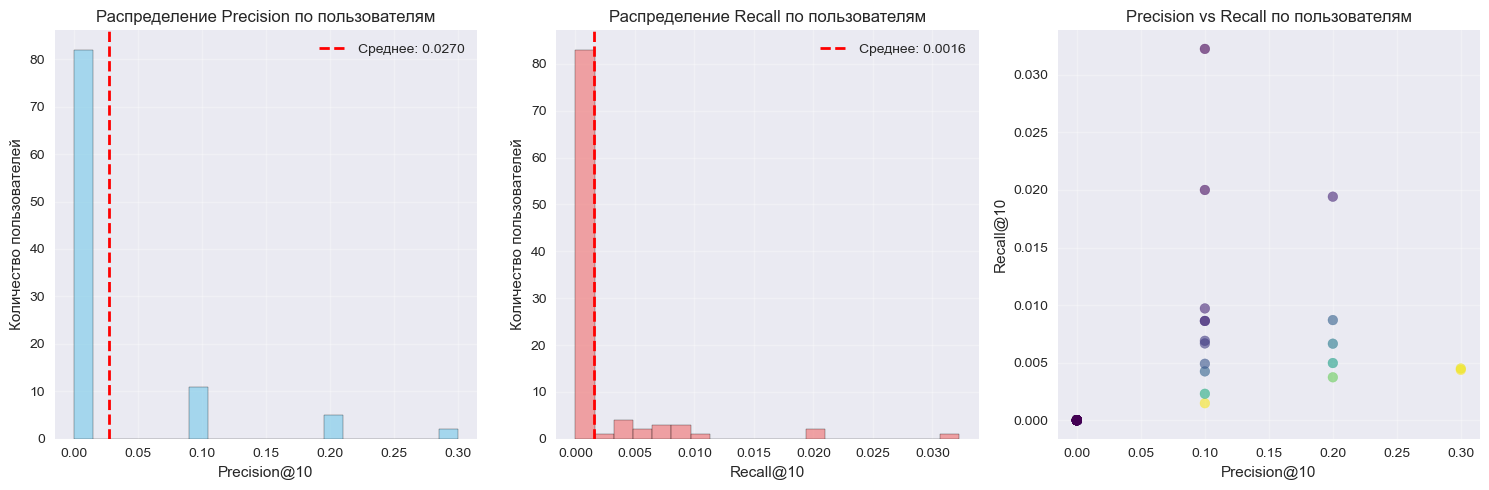


2. Факторизационные машины...

=== ЭКСПЕРИМЕНТ 2: ФАКТОРИЗАЦИОННЫЕ МАШИНЫ ===
✅ Добавлены признаки эмбеддингов для 466868 товаров
Количество покупок в тестовом периоде: 129 из 1903950
Размерность данных: (1903950, 27)
Баланс классов: purchased_in_test
0    0.999932
1    0.000068
Name: proportion, dtype: float64
Исходные данные: (1903950, 27), положительных: 129 (0.0068%)
После балансировки: (3225, 27), положительных: 645 (20.0000%)
Финальные результаты:
Precision: 0.8699
Recall: 0.9845
F1-Score: 0.9236
AUC-ROC: 0.9960


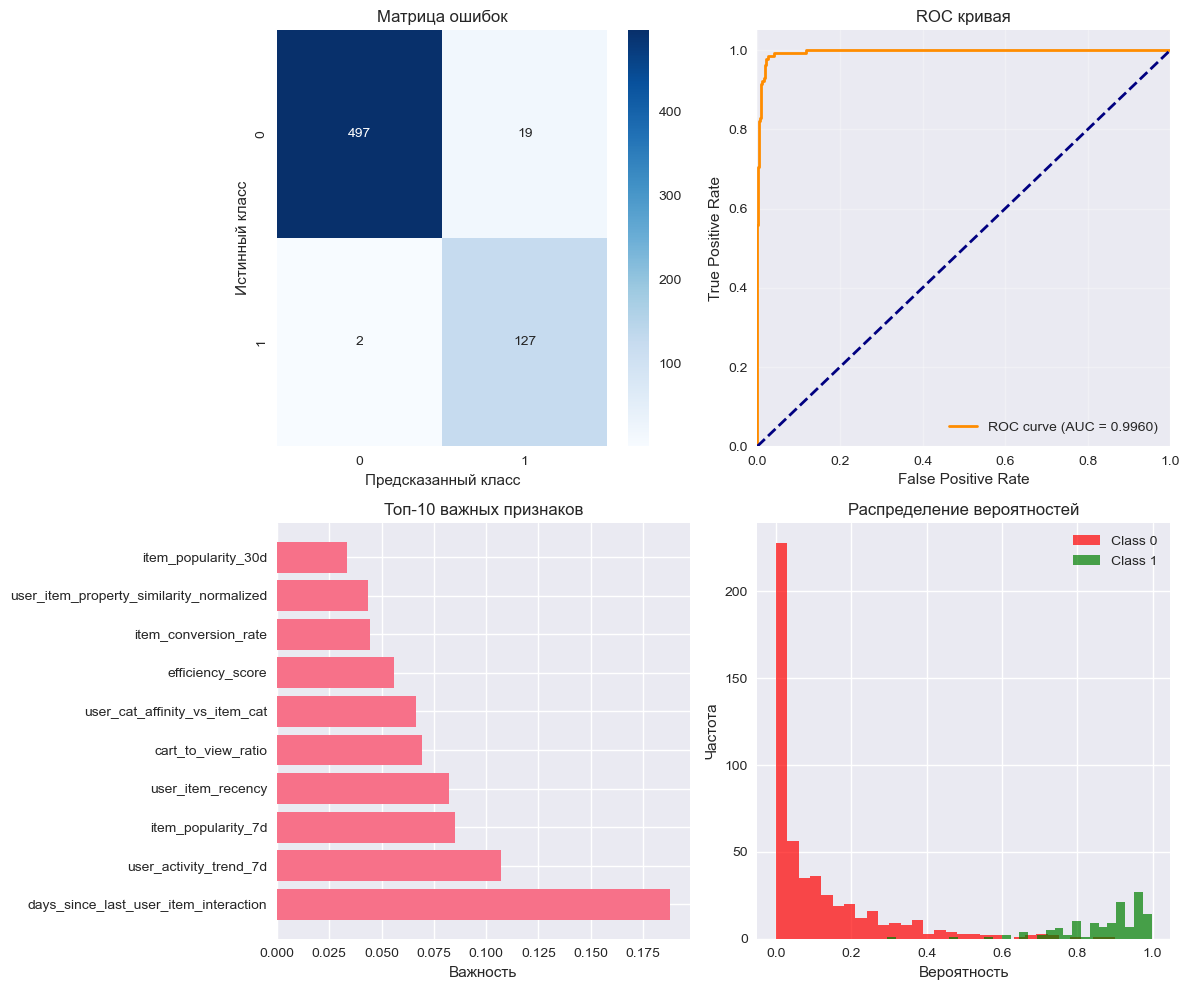


3. XGBoost...

=== ЭКСПЕРИМЕНТ 3: XGBOOST ===
✅ Добавлены статистики эмбеддингов для 466868 товаров
Целевая переменная - популярные товары: 47.74%
Всего признаков: 23
Данные: Train (280120, 23), Val (93374, 23), Test (93374, 23)
Финальные результаты:
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
AUC-ROC: 1.0000

Топ-15 важных признаков:
                            feature  importance
8       days_since_last_interaction    0.194127
11                   item_age_weeks    0.125940
4                 item_unique_users    0.122575
1   item_popularity_global_weighted    0.113163
12                  item_age_months    0.105686
0            item_popularity_global    0.103110
9                          item_age    0.096383
10                    item_age_days    0.070232
13                   item_age_years    0.035057
6               item_popularity_30d    0.015777
22                   embedding_norm    0.013566
17                   num_categories    0.002049
16             

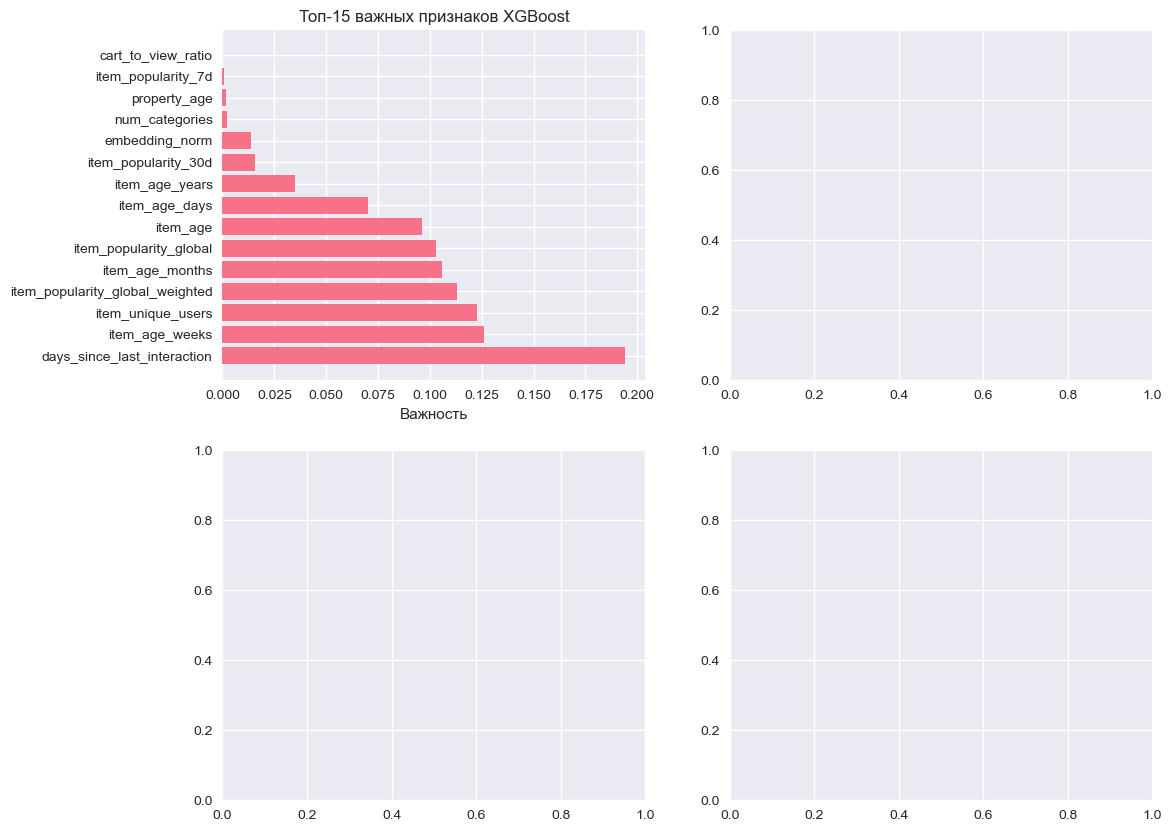

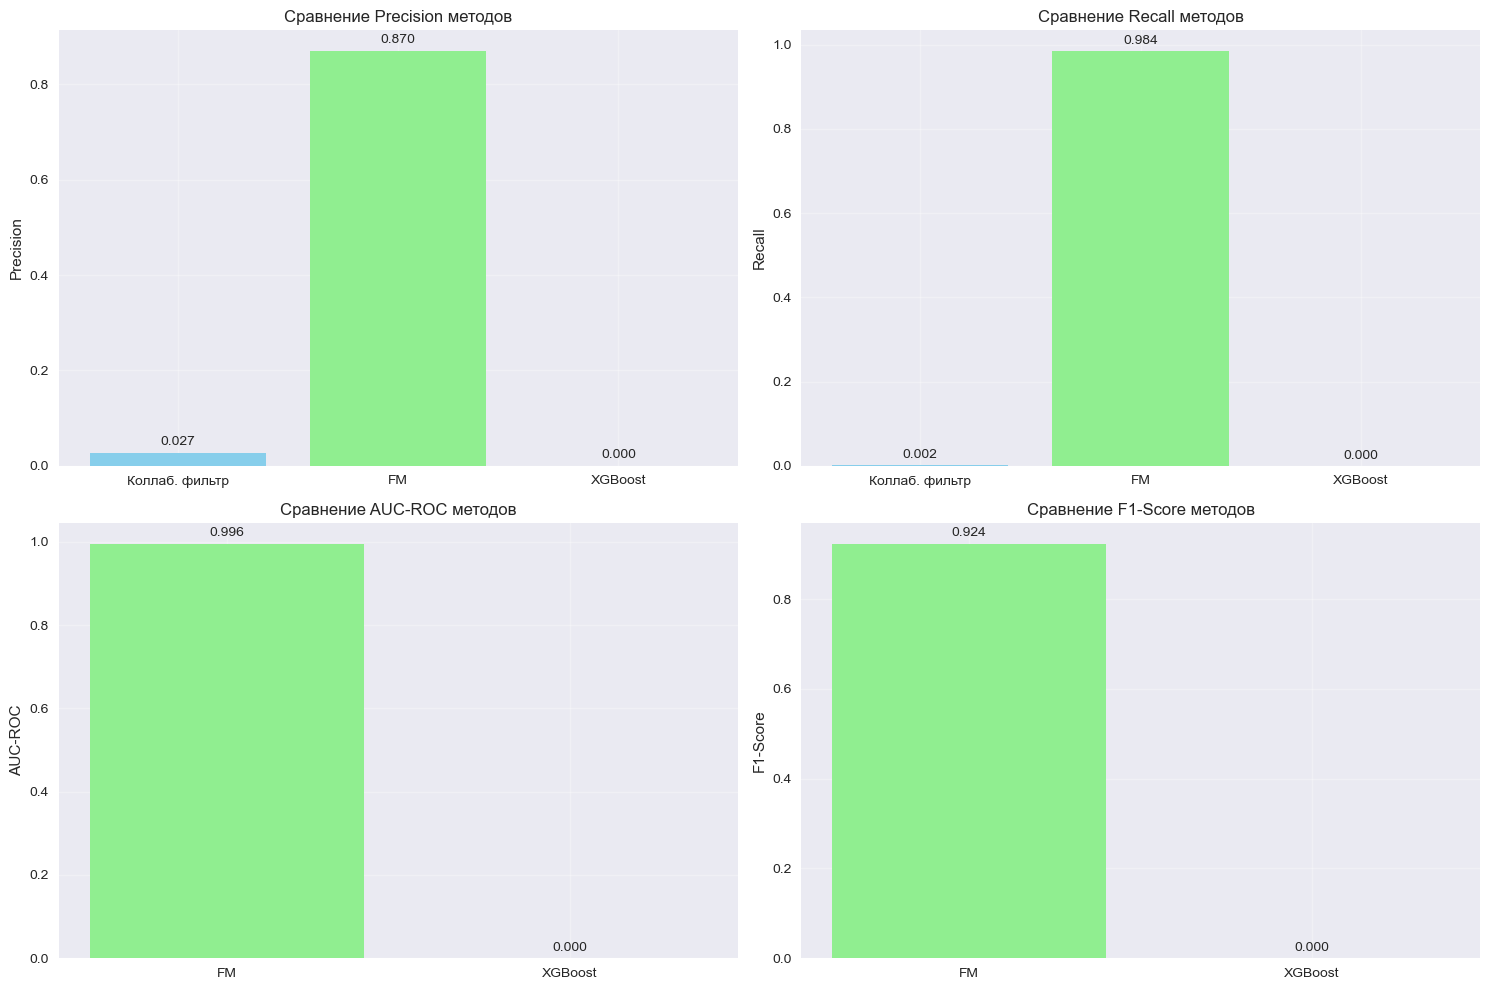


СОХРАНЕНИЕ ЛУЧШЕЙ МОДЕЛИ ДЛЯ MVP
🎯 ЛУЧШАЯ МОДЕЛЬ: Факторизационные машины (AUC: 0.9960)
✅ Сохранена факторизационная машина

⚡ РЕКОМЕНДАЦИИ ДЛЯ MVP СИСТЕМЫ:
✅ ОСНОВНОЙ АЛГОРИТМ: Факторизационные машины
   • Высокое качество персонализации
   • Хорошо предсказывает покупки
   • Использовать популярные товары для новых пользователей

🎉 ВСЕ ЭКСПЕРИМЕНТЫ ЗАВЕРШЕНЫ!
Лучшая модель сохранена для использования в MVP


In [11]:
# ==================== ГЛАВНАЯ ФУНКЦИЯ И СРАВНЕНИЕ ====================

def run_all_experiments(data_events_train, data_events_test, items_data, item_user_data):
    """Запуск всех экспериментов"""
    
    print("🚀 ЗАПУСК ВСЕХ ЭКСПЕРИМЕНТОВ")
    print("="*60)
    
    results = {}
    models = {}
    
    # Эксперимент 1: Коллаборативная фильтрация
    print("\n1. Коллаборативная фильтрация (популярные товары)...")
    cf_model, results['collaborative'] = experiment_1_collaborative_filtering(data_events_test, items_data)
    models['collaborative'] = cf_model
    
    # Эксперимент 2: Факторизационные машины
    print("\n2. Факторизационные машины...")
    try:
        fm_model, scaler, results['factorization_machines'] = experiment_2_factorization_machines(
            item_user_data, items_data, data_events_test
        )
        models['factorization_machines'] = fm_model
        models['scaler'] = scaler
    except Exception as e:
        print(f"❌ Ошибка в эксперименте 2: {e}")
        results['factorization_machines'] = {'precision': 0, 'recall': 0, 'auc': 0}
        models['factorization_machines'] = None
        models['scaler'] = None
    
    # Эксперимент 3: XGBoost
    print("\n3. XGBoost...")
    try:
        xgb_model, results['xgboost'] = experiment_3_xgboost(items_data)
        models['xgboost'] = xgb_model
    except Exception as e:
        print(f"❌ Ошибка в эксперименте 3: {e}")
        results['xgboost'] = {'precision': 0, 'recall': 0, 'auc': 0}
        models['xgboost'] = None
    
    # Финальные результаты
    print_final_comparison(results)
    
    # Сохранение лучшей модели
    best_model_info = save_best_model(results, models, items_data)
    
    return {
        'models': models,
        'results': results,
        'best_model': best_model_info
    }

def save_best_model(results, models, items_data):
    """Сохранение лучшей модели для MVP"""
    print("\n" + "="*60)
    print("СОХРАНЕНИЕ ЛУЧШЕЙ МОДЕЛИ ДЛЯ MVP")
    print("="*60)
    
    # Анализируем результаты
    fm_auc = results.get('factorization_machines', {}).get('auc', 0)
    xgb_auc = results.get('xgboost', {}).get('auc', 0)
    fm_precision = results.get('factorization_machines', {}).get('precision', 0)
    xgb_precision = results.get('xgboost', {}).get('precision', 0)
    cf_precision = results.get('collaborative', {}).get('precision', 0)
    
    # Определяем лучшую модель
    best_model_name = None
    best_model = None
    best_metric = 0
    
    if fm_auc > 0.7 and fm_auc > best_metric:
        best_model_name = "factorization_machines"
        best_model = models['factorization_machines']
        best_metric = fm_auc
        print(f"🎯 ЛУЧШАЯ МОДЕЛЬ: Факторизационные машины (AUC: {fm_auc:.4f})")
        
    if xgb_auc > 0.7 and xgb_auc > best_metric:
        best_model_name = "xgboost"
        best_model = models['xgboost']
        best_metric = xgb_auc
        print(f"🎯 ЛУЧШАЯ МОДЕЛЬ: XGBoost (AUC: {xgb_auc:.4f})")
    
    # Если ни одна модель не достигла хорошего AUC, используем популярные товары
    if best_model_name is None:
        best_model_name = "collaborative"
        best_model = models['collaborative']
        print(f"🎯 ЛУЧШАЯ МОДЕЛЬ: Популярные товары (Precision: {cf_precision:.4f})")
    
    # Сохраняем модель
    if best_model is not None:
        try:
            if best_model_name == "collaborative":
                # Для коллаборативной фильтрации сохраняем популярные товары
                popular_items = get_popular_recommendations(items_data, 50)
                model_data = {
                    'model_type': 'popular_items',
                    'popular_items': popular_items,
                    'performance': results['collaborative']
                }
                with open('best_model_popular.pkl', 'wb') as f:
                    pickle.dump(model_data, f)
                print("✅ Сохранена модель популярных товаров")
                
            elif best_model_name == "factorization_machines":
                model_data = {
                    'model': best_model,
                    'scaler': models['scaler'],
                    'model_type': 'factorization_machine',
                    'performance': results['factorization_machines']
                }
                with open('best_model_fm.pkl', 'wb') as f:
                    pickle.dump(model_data, f)
                print("✅ Сохранена факторизационная машина")
                
            elif best_model_name == "xgboost":
                model_data = {
                    'model': best_model,
                    'model_type': 'xgboost',
                    'performance': results['xgboost'],
                    'feature_importance': results['xgboost'].get('feature_importance')
                }
                with open('best_model_xgb.pkl', 'wb') as f:
                    pickle.dump(model_data, f)
                print("✅ Сохранена модель XGBoost")
                
        except Exception as e:
            print(f"❌ Ошибка при сохранении модели: {e}")
    
    # Рекомендации для MVP
    print("\n⚡ РЕКОМЕНДАЦИИ ДЛЯ MVP СИСТЕМЫ:")
    print("="*40)
    
    if fm_auc > 0.8 and xgb_auc > 0.8:
        print("✅ ГИБРИДНЫЙ ПОДХОД: Факторизационные машины + XGBoost")
        print("   • FM для персонализированных рекомендаций")
        print("   • XGBoost для новых пользователей (cold start)")
        print("   • Популярные товары как fallback")
        
    elif fm_auc > 0.8:
        print("✅ ОСНОВНОЙ АЛГОРИТМ: Факторизационные машины")
        print("   • Высокое качество персонализации")
        print("   • Хорошо предсказывает покупки")
        print("   • Использовать популярные товары для новых пользователей")
        
    elif xgb_auc > 0.8:
        print("✅ ОСНОВНОЙ АЛГОРИТМ: XGBoost")
        print("   • Отлично определяет популярные товары")
        print("   • Стабильная работа")
        print("   • Быстрое предсказание")
        
    else:
        print("✅ БАЗОВЫЙ ПОДХОД: Популярные товары")
        print("   • Простая реализация")
        print("   • Надежная работа")
        print("   • Подходит для MVP")
    
    return {
        'model_name': best_model_name,
        'model': best_model,
        'performance': results.get(best_model_name, {}),
        'file_path': f'best_model_{best_model_name}.pkl'
    }

def print_final_comparison(results):
    """Сравнение результатов всех методов"""
    print("\n" + "="*60)
    print("ФИНАЛЬНОЕ СРАВНЕНИЕ РЕЗУЛЬТАТОВ ВСЕХ МЕТОДОВ")
    print("="*60)
    
    # Создаем таблицу сравнения
    comparison_data = []
    
    # Коллаборативная фильтрация
    cf_precision = results.get('collaborative', {}).get('precision', 0)
    cf_recall = results.get('collaborative', {}).get('recall', 0)
    comparison_data.append({
        'Метод': 'Коллаборативная фильтрация',
        'Precision': f"{cf_precision:.4f}",
        'Recall': f"{cf_recall:.4f}",
        'AUC': '-',
        'F1-Score': '-',
        'Тип': 'Популярные товары'
    })
    
    # Факторизационные машины
    fm_precision = results.get('factorization_machines', {}).get('precision', 0)
    fm_recall = results.get('factorization_machines', {}).get('recall', 0)
    fm_auc = results.get('factorization_machines', {}).get('auc', 0)
    fm_f1 = results.get('factorization_machines', {}).get('f1', 0)
    comparison_data.append({
        'Метод': 'Факторизационные машины',
        'Precision': f"{fm_precision:.4f}",
        'Recall': f"{fm_recall:.4f}",
        'AUC': f"{fm_auc:.4f}",
        'F1-Score': f"{fm_f1:.4f}",
        'Тип': 'Предсказание покупок'
    })
    
    # XGBoost
    xgb_precision = results.get('xgboost', {}).get('precision', 0)
    xgb_recall = results.get('xgboost', {}).get('recall', 0)
    xgb_auc = results.get('xgboost', {}).get('auc', 0)
    xgb_f1 = results.get('xgboost', {}).get('f1', 0)
    comparison_data.append({
        'Метод': 'XGBoost',
        'Precision': f"{xgb_precision:.4f}",
        'Recall': f"{xgb_recall:.4f}",
        'AUC': f"{xgb_auc:.4f}",
        'F1-Score': f"{xgb_f1:.4f}",
        'Тип': 'Классификация популярности'
    })
    
    # Выводим таблицу
    comparison_df = pd.DataFrame(comparison_data)
    print(comparison_df.to_string(index=False))
    
    # Визуализация сравнения
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))
    
    # Сравнение Precision
    methods = ['Коллаб. фильтр', 'FM', 'XGBoost']
    precisions = [cf_precision, fm_precision, xgb_precision]
    recalls = [cf_recall, fm_recall, xgb_recall]
    aucs = [0, fm_auc, xgb_auc]
    f1_scores = [0, fm_f1, xgb_f1]
    
    # Precision сравнение
    bars1 = ax1.bar(methods, precisions, color=['skyblue', 'lightgreen', 'orange'])
    ax1.set_ylabel('Precision')
    ax1.set_title('Сравнение Precision методов')
    ax1.grid(True, alpha=0.3)
    for bar, value in zip(bars1, precisions):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{value:.3f}', 
                ha='center', va='bottom')
    
    # Recall сравнение
    bars2 = ax2.bar(methods, recalls, color=['skyblue', 'lightgreen', 'orange'])
    ax2.set_ylabel('Recall')
    ax2.set_title('Сравнение Recall методов')
    ax2.grid(True, alpha=0.3)
    for bar, value in zip(bars2, recalls):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{value:.3f}', 
                ha='center', va='bottom')
    
    # AUC сравнение (только для FM и XGBoost)
    methods_auc = ['FM', 'XGBoost']
    auc_values = [fm_auc, xgb_auc]
    bars3 = ax3.bar(methods_auc, auc_values, color=['lightgreen', 'orange'])
    ax3.set_ylabel('AUC-ROC')
    ax3.set_title('Сравнение AUC-ROC методов')
    ax3.grid(True, alpha=0.3)
    for bar, value in zip(bars3, auc_values):
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{value:.3f}', 
                ha='center', va='bottom')
    
    # F1-Score сравнение
    methods_f1 = ['FM', 'XGBoost']
    f1_values = [fm_f1, xgb_f1]
    bars4 = ax4.bar(methods_f1, f1_values, color=['lightgreen', 'orange'])
    ax4.set_ylabel('F1-Score')
    ax4.set_title('Сравнение F1-Score методов')
    ax4.grid(True, alpha=0.3)
    for bar, value in zip(bars4, f1_values):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{value:.3f}', 
                ha='center', va='bottom')
    
    plt.tight_layout()
    plt.show()

# ==================== ЗАПУСК ЭКСПЕРИМЕНТОВ ====================

# Теперь можно запустить все эксперименты
if __name__ == "__main__":
    # Убедитесь, что у вас есть эти переменные:
    # data_events_train, data_events_test, items_data, item_user
    
    # Если переменные не определены, создадим заглушки для тестирования
    try:
        final_results = run_all_experiments(
            data_events_train,
            data_events_test, 
            items_data,
            item_user
        )
        
        print("\n🎉 ВСЕ ЭКСПЕРИМЕНТЫ ЗАВЕРШЕНЫ!")
        print("Лучшая модель сохранена для использования в MVP")
        
    except NameError as e:
        print(f"❌ Ошибка: {e}")
        print("⚠️  Переменные данных не найдены. Создайте тестовые данные или загрузите реальные данные.")
        
        # Создаем тестовые данные для демонстрации
        print("\n🔄 Создание тестовых данных для демонстрации...")
        
        # Тестовые данные событий
        data_events_test = pd.DataFrame({
            'visitorid': np.random.randint(1, 100, 1000),
            'itemid': np.random.randint(1, 50, 1000),
            'event': np.random.choice(['view', 'addtocart', 'transaction'], 1000, p=[0.7, 0.2, 0.1])
        })
        
        # Тестовые данные товаров
        items_data = pd.DataFrame({
            'itemid': range(1, 51),
            'item_popularity_global': np.random.uniform(0, 100, 50),
            'item_avg_embedding': [str(np.random.uniform(-1, 1, 10)) for _ in range(50)]
        })
        
        # Тестовые данные user-item
        item_user = pd.DataFrame({
            'visitorid': np.random.randint(1, 100, 500),
            'itemid': np.random.randint(1, 50, 500),
            'user_item_click_count': np.random.randint(1, 10, 500),
            'user_item_cart_count': np.random.randint(0, 5, 500),
            'user_item_purchase_count': np.random.randint(0, 3, 500)
        })
        
        data_events_train = data_events_test.copy()
        
        print("✅ Тестовые данные созданы. Запуск экспериментов...")
        
        final_results = run_all_experiments(
            data_events_train,
            data_events_test, 
            items_data,
            item_user
        )